# Capitolo 13 — Feature, prototipi e prompt: esperimenti controllati

Arcangelo Distante e Cosimo Distante · **Computer Vision**

I vettori e le maschere sono assegnati. Non si eseguono DINO, MAE o SAM e non si simulano loro prestazioni. Il prompt compare come informazione e regola di selezione, senza un decoder appreso.

## Avvio in Google Colab o in locale

Aprire questo file in Colab e selezionare un runtime Python su CPU; non è richiesta una GPU. Usare **Esegui tutto** dall’inizio. Le dipendenze sono NumPy e Matplotlib, già normalmente presenti in Colab; in un ambiente locale installarle con `python -m pip install numpy matplotlib`.

I dati vengono costruiti nelle celle: non occorre caricare file, checkpoint o figure del libro. Per ripartire, riavviare il runtime ed eseguire tutte le celle in ordine. La cartella relativa `output_capitolo13` conserva JSON, CSV e figure; in Colab scaricarla prima di terminare la sessione. Le variabili intermedie non persistono dopo il riavvio.

Le istruzioni per Colab descrivono la procedura di avvio; non attribuiscono al servizio misure effettuate altrove.

In [1]:
from pathlib import Path
import json, platform
import numpy as np
import matplotlib.pyplot as plt

output = Path('output_capitolo13')
output.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
plt.rcParams.update({'font.size': 11, 'figure.figsize': (7, 4)})
def salva_json(nome, dati):
    (output / nome).write_text(json.dumps(dati, indent=2, ensure_ascii=False,
        allow_nan=False, default=lambda v: np.asarray(v).tolist()), encoding='utf-8')
salva_json('ambiente.json', {'python': platform.python_version(), 'numpy': np.__version__,
                           'dispositivo': 'CPU', 'dati': 'sintetici autocontenuti'})
print('Output:', output)


Output: output_capitolo13


## A — Prototipi normalizzati

Normalizziamo ogni elemento del support, ne calcoliamo la media per classe e normalizziamo ancora. La query resta separata. La terza query è intenzionalmente ambigua per simmetria.

In [2]:
def unit(X):
    X=np.asarray(X,float); lengths=np.linalg.norm(X,axis=-1,keepdims=True)
    if np.any(lengths==0): raise ValueError('Il coseno non è definito per feature nulle')
    return X/lengths
support=np.array([[1,0],[.8,.2],[0,1],[.2,.8]],float); labels=np.array([0,0,1,1])
support_unit=unit(support)
prototypes=unit(np.stack([support_unit[labels==c].mean(0) for c in [0,1]]))
queries=unit([[.9,.1],[.1,.9],[.5,.5]]); scores=queries@prototypes.T
pred=scores.argmax(1); ties=np.isclose(scores[:,0],scores[:,1],rtol=0,atol=1e-12)
assert np.allclose(prototypes[0],prototypes[1,::-1]) and ties[-1]
print('Prototipi:',prototypes,'\nCoseni:',scores,'\nPareggi:',ties)
salva_json('prototipi.json',{'prototipi':prototypes,'coseni':scores,'argmax':pred,'pareggi':ties})
np.savetxt(output/'coseni.csv',scores,delimiter=',',header='classe0,classe1',comments='')


Prototipi: [[0.99250756 0.12218326]
 [0.12218326 0.99250756]] 
Coseni: [[0.99993    0.23104008]
 [0.23104008 0.99993   ]
 [0.78820544 0.78820544]] 
Pareggi: [False False  True]


### Interpretazione

N13.A.1 — Quale informazione annotata viene usata anche se l’encoder non è addestrato?

N13.A.2 — Perché il pareggio non può essere presentato come una previsione sicura della classe zero?

## B — Relazioni e corrispondenze

Una rotazione dello spazio delle componenti non altera le relazioni fra feature. Permutare le posizioni è un’altra operazione e richiede di riallineare le righe prima del confronto.

{'G': array([[1. , 0.8, 0. ],
       [0.8, 1. , 0.6],
       [0. , 0.6, 1. ]]), 'errore_rotazione_max': np.float64(2.220446049250313e-16), 'loss_permutazione_senza_riallineamento': np.float64(1.44)}


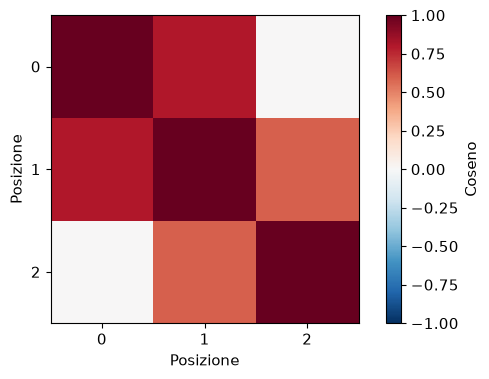

In [3]:
X=np.array([[1.,0.],[.8,.6],[0.,1.]])
theta=np.pi/3; Q=np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])
G=X@X.T; Grot=(X@Q)@(X@Q).T
perm=[1,0,2]; Gperm=X[perm]@X[perm].T
gram={'G':G,'errore_rotazione_max':np.max(np.abs(G-Grot)),
      'loss_permutazione_senza_riallineamento':np.sum((G-Gperm)**2)}
assert np.allclose(G,Grot) and np.isclose(gram['loss_permutazione_senza_riallineamento'],1.44)
print(gram); salva_json('gram.json',gram)
fig,ax=plt.subplots();im=ax.imshow(G,vmin=-1,vmax=1,cmap='RdBu_r');fig.colorbar(im,ax=ax,label='Coseno');ax.set(xlabel='Posizione',ylabel='Posizione',xticks=[0,1,2],yticks=[0,1,2]);fig.savefig(output/'gram.png',dpi=180,bbox_inches='tight');plt.show()


### Interpretazione

N13.B.1 — Dimostrare l’invarianza usando QQᵀ=I e spiegare l’errore numerico residuo.

N13.B.2 — Perché la loss della matrice permutata non prova un peggioramento delle feature?

## C — Maschere, selezione e costo informativo

La maschera target e una predizione binaria sono assegnate. Tre ulteriori coppie score/IoU illustrano la selezione del candidato; non sono output di SAM.

In [4]:
target=np.zeros(60,bool); target[:50]=True
mask=np.zeros(60,bool); mask[20:60]=True
intersection=np.logical_and(target,mask).sum(); union=np.logical_or(target,mask).sum()
score=np.array([.91,.84,.73]); true_iou=np.array([.62,.88,.70])
chosen=int(score.argmax()); oracle=int(true_iou.argmax())
prompt={'intersezione':int(intersection),'unione':int(union),
        'IoU':intersection/union,'Dice':2*intersection/(target.sum()+mask.sum()),
        'candidato_operativo':chosen+1,'IoU_operativa':true_iou[chosen],
        'candidato_oracle':oracle+1,'IoU_oracle':true_iou[oracle],
        'costo_assegnato_cache_s':1.2+5*.1,'costo_assegnato_senza_cache_s':5*(1.2+.1)}
assert np.isclose(prompt['IoU'],.5) and np.isclose(prompt['Dice'],2/3)
print(prompt); salva_json('prompt.json',prompt)


{'intersezione': 30, 'unione': 60, 'IoU': np.float64(0.5), 'Dice': np.float64(0.6666666666666666), 'candidato_operativo': 1, 'IoU_operativa': np.float64(0.62), 'candidato_oracle': 2, 'IoU_oracle': np.float64(0.88), 'costo_assegnato_cache_s': 1.7, 'costo_assegnato_senza_cache_s': 6.5}


### Interpretazione

N13.C.1 — Perché scegliere il massimo della IoU vera cambia l’informazione disponibile alla pipeline?

N13.C.2 — Interpretare il risparmio di cache e indicare quali costi umani o di sistema restano esclusi.

## Conservare e interpretare gli output

Controllare i file nella cartella di output e scaricarli insieme al notebook se si usa un runtime temporaneo. JSON e CSV distinguono valori analitici assegnati, campioni sintetici e risultati dei calcoli. Le verifiche numeriche non stimano le prestazioni dei modelli reali. Per studiarli occorrono pesi, dati, licenze e un protocollo separato.

## Risorse primarie e implementazioni ufficiali

- [DINO, codice degli autori](https://github.com/facebookresearch/dino)

- [MAE, codice degli autori](https://github.com/facebookresearch/mae)

- [SAM 2, codice degli autori](https://github.com/facebookresearch/sam2)